# 01 – EDA: BCSC Risk Factors (Breast Cancer Awareness Month)

Each row is a covariate pattern; `count` is the number of mammography observations with that pattern, so every statistic here is **weighted by `count`**. Requires `python src/clean.py` to have been run.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
df = pd.read_parquet(ROOT / "data/processed/bcsc_clean.parquet")
FIG_DIR = ROOT / "output"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(f"{len(df):,} rows, {df['count'].sum():,} observations")

1,522,340 rows, 6,788,436 observations


## Weighted distribution of each variable (% of observations, unknowns included)

In [2]:
def weighted_dist(col):
    s = df[col].cat.add_categories("Unknown").fillna("Unknown") if df[col].isna().any() else df[col]
    return (df.groupby(s, observed=True)["count"].sum() / df["count"].sum() * 100).round(1)

label_cols = [c for c in df.columns if c.endswith("_label")]
for col in label_cols:
    print(f"\n{col.removesuffix('_label')}")
    print(weighted_dist(col).to_string())


age_group_5_years
age_group_5_years_label
18-29     0.2
30-34     0.6
35-39     2.4
40-44    11.3
45-49    13.4
50-54    15.1
55-59    15.0
60-64    13.4
65-69    11.1
70-74     7.9
75-79     5.3
80-84     3.0
85+       1.5

race_eth
race_eth_label
Non-Hispanic white        66.6
Non-Hispanic black        10.9
Asian/Pacific Islander     9.8
Native American            0.3
Hispanic                   5.5
Other/mixed                1.6
Unknown                    5.2

first_degree_hx
first_degree_hx_label
No         79.1
Yes        16.4
Unknown     4.5

age_menarche
age_menarche_label
>=14       10.8
12-13      20.3
<12         7.6
Unknown    61.3

age_first_birth
age_first_birth_label
<20            10.2
20-24          15.3
25-29          11.8
>=30           13.7
Nulliparous    16.5
Unknown        32.5

BIRADS_breast_density
BIRADS_breast_density_label
Almost entirely fat                    8.4
Scattered fibroglandular densities    38.3
Heterogeneously dense                 34.7
Extremely 

## Observations per year

In [3]:
df.groupby('year')['count'].sum().to_frame('observations')

,observations
year,
2005,582084
2006,580850
2007,580120
2008,592821
2009,599946
2010,566672
2011,508375
2012,505924
2013,525671


## Share of screening mammograms with high mammographic density (BI-RADS 3–4), by age group

Among observations with known density.

In [4]:
known = df[df["high_density"].notna()]
by_age = (known.assign(dense_w=known["high_density"] * known["count"])
               .groupby("age_group_5_years_label", observed=True)[["dense_w", "count"]].sum())
by_age["dense_share"] = by_age["dense_w"] / by_age["count"]
overall = by_age["dense_w"].sum() / by_age["count"].sum()
by_age[["count", "dense_share"]]

,count,dense_share
age_group_5_years_label,,
18-29,8592,0.712989
30-34,35845,0.720854
35-39,137400,0.696434
40-44,672479,0.664531
45-49,803791,0.631215
50-54,905570,0.525436
55-59,898591,0.43788
60-64,807372,0.388722
65-69,676095,0.352269


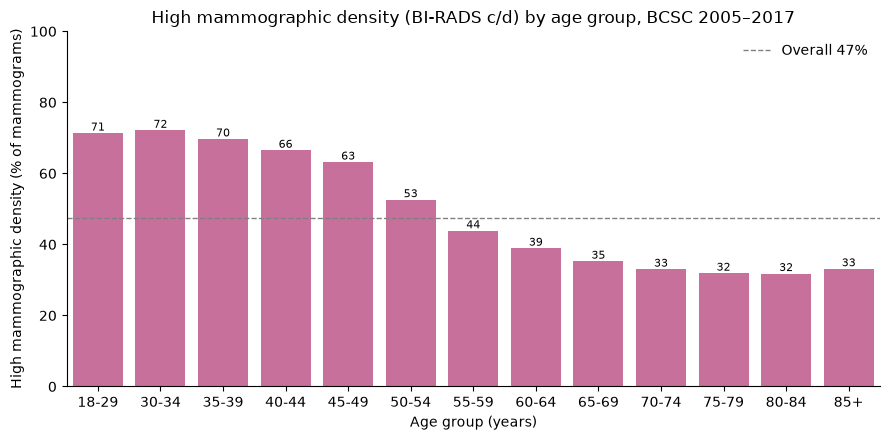

In [5]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(x=by_age.index.astype(str), y=by_age["dense_share"] * 100, color="#d6619b", ax=ax)
ax.axhline(overall * 100, ls="--", c="grey", lw=1, label=f"Overall {overall:.0%}")
ax.set(xlabel="Age group (years)", ylabel="High mammographic density (% of mammograms)", ylim=(0, 100),
       title="High mammographic density (BI-RADS c/d) by age group, BCSC 2005–2017")
ax.bar_label(ax.containers[0], fmt="%.0f", fontsize=8)
ax.legend(frameon=False)
sns.despine()
fig.tight_layout()
fig.savefig(FIG_DIR / "high_density_by_age.png", dpi=150)